# Routex: Notebook 03, Exploratory Data Analysis (EDA)

**Project:** Routex, machine-learning-based vehicle fuel consumption prediction
**Author:** Member 2
**Target:** `comb08`, combined city/highway fuel economy (MPG)

This notebook explores the data to understand **what drives fuel economy** and what
that means for the models we will train. It builds on the decisions made in
[`02_preprocessing.ipynb`](02_preprocessing.ipynb):

- pure electric vehicles are excluded (their `comb08` is MPGe, not MPG),
- target-leakage columns (city/highway MPG, fuel cost, CO2, ...) are never used,
- the cleaned features come from `src/preprocessing.py`.

### Avoiding leakage in the EDA itself

EDA findings shape modelling choices. If we looked at the **test set** while exploring,
those choices would be partly based on data the model is supposed to never have seen,
and the final test score would be optimistic. So:

- **Section 1** describes the *original* dataset (sizes, columns, EV context).
- **Every analysis after that uses the training split only** (80%, `random_state=42`),
  which is exactly the same split as in notebook 02. The test set is not looked at here.
- Leakage columns appear only in the overview, never as candidate predictors.

All figures are saved to `reports/figures/03_*.png`.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import preprocessing as prep

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# ---- Chart style: one consistent, colour-blind-safe system for every figure ----
BLUE = "#257de0"            # single-series colour
SERIES = ["#257de0", "#f47230", "#00b894"]   # categorical slots 1-3 (fixed order)
TEXT, TEXT_2, GRID = "#191919", "#666666", "#e6e6e6"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#1757ac", "#84b9f3", "#efefef", "#f39a9a", "#c22f30"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titlecolor": TEXT,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "legend.frameon": False,
})

def save(fig, name):
    # Save a figure to reports/figures with a consistent file name.
    fig.savefig(FIGURES_DIR / f"03_{name}.png")

print("pandas", pd.__version__, "| seaborn", sns.__version__, "| random_state", prep.RANDOM_STATE)

pandas 3.1.1 | seaborn 0.13.2 | random_state 42


## 1. Dataset overview and dimensions

We load the original file and apply the rule-based cleaning from notebook 02
(EV exclusion, duplicate removal, feature engineering, dropping leakage/ID columns).

In [2]:
raw = prep.load_raw_data()
clean, clean_report = prep.clean_dataset(raw)
X_train, X_test, y_train, y_test = prep.split_features_target(clean)

# The EDA data set: training features + target. The test set is not used below.
train = X_train.assign(comb08=y_train).reset_index(drop=True)
TARGET = prep.TARGET

overview = pd.DataFrame({
    "rows": [len(raw), len(clean), len(train), len(X_test)],
    "columns": [raw.shape[1], clean.shape[1], train.shape[1], X_test.shape[1] + 1],
}, index=["original dataset", "after cleaning", "training split (used for EDA)",
          "test split (held out, not analysed)"])
overview

,rows,columns
original dataset,42774,83
after cleaning,42493,23
training split (used for EDA),33994,23
"test split (held out, not analysed)",8499,23


In [3]:
print("Rows removed during cleaning:")
for k in ("rows_removed_pure_ev", "rows_removed_duplicates"):
    print(f"  {k:<26} {clean_report[k]}")

column_groups = prep.column_accounting(raw.columns)["decision"].str.split(":").str[0].value_counts()
print("\nWhat happened to the 83 original columns:")
print(column_groups.to_string())

print(f"\nModel inputs: {len(prep.NUMERIC_FEATURES)} numerical, {len(prep.BINARY_FEATURES)} binary, "
      f"{len(prep.CATEGORICAL_FEATURES)} categorical = {len(prep.FEATURES)} features")
print(f"Model years covered: {train['year'].min()} to {train['year'].max()}")

Rows removed during cleaning:
  rows_removed_pure_ev       241
  rows_removed_duplicates    40

What happened to the 83 original columns:
decision
dropped    67
kept       15
target      1

Model inputs: 6 numerical, 4 binary, 12 categorical = 22 features
Model years covered: 1984 to 2021


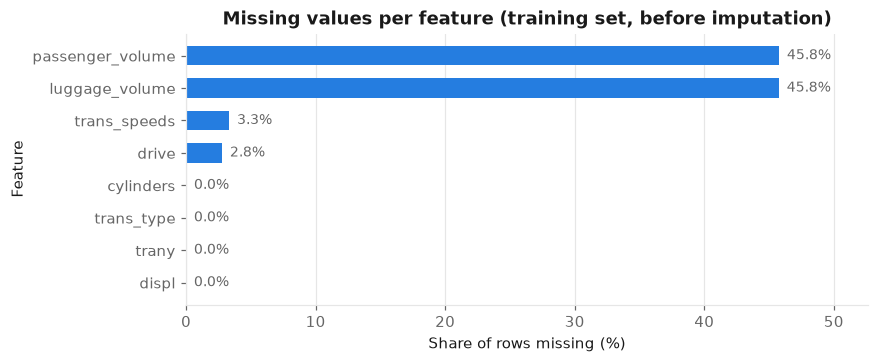

In [4]:
missing = train[prep.FEATURES].isna().mean().mul(100).sort_values(ascending=True)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for y, v in enumerate(missing.values):
    ax.text(v + 0.6, y, f"{v:.1f}%", va="center", color=TEXT_2, fontsize=9)
ax.set_title("Missing values per feature (training set, before imputation)")
ax.set_xlabel("Share of rows missing (%)")
ax.set_ylabel("Feature")
ax.set_xlim(0, missing.max() * 1.15)
ax.grid(axis="y", visible=False)
save(fig, "missing_values")
plt.show()

**Observations:**

- Only 8 of the 22 features have any missing values, and only two have a lot:
  `passenger_volume` and `luggage_volume` (about 46%). Section 8.3 shows these gaps are
  **not random**.
- `drive` is missing for 2.8% of rows, all from model year 1984.
- `trans_speeds` is missing for 3.3% of rows. These are mostly continuously variable
  transmissions (CVTs), which have no fixed number of gears. A separate feature,
  `is_cvt`, records whether a car has a CVT.
- All other gaps are tiny. In the model, the preprocessing pipeline fills them in
  using values from the training data only.

## 2. Numerical feature distributions

In [5]:
num_summary = train[prep.NUMERIC_FEATURES].describe().T
num_summary["skew"] = train[prep.NUMERIC_FEATURES].skew()
num_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
year,33994.0,2002.22,11.49,1984.0,1992.0,2003.0,2012.0,2021.0,-0.07
displ,33992.0,3.29,1.36,0.6,2.2,3.0,4.3,8.4,0.66
cylinders,33991.0,5.71,1.76,2.0,4.0,6.0,6.0,16.0,0.89
trans_speeds,32861.0,5.12,1.41,1.0,4.0,5.0,6.0,10.0,0.87
passenger_volume,18432.0,91.33,11.20,1.0,85.0,91.0,98.0,195.0,-0.18
luggage_volume,18437.0,16.04,8.00,1.0,12.0,14.0,17.0,55.0,1.84


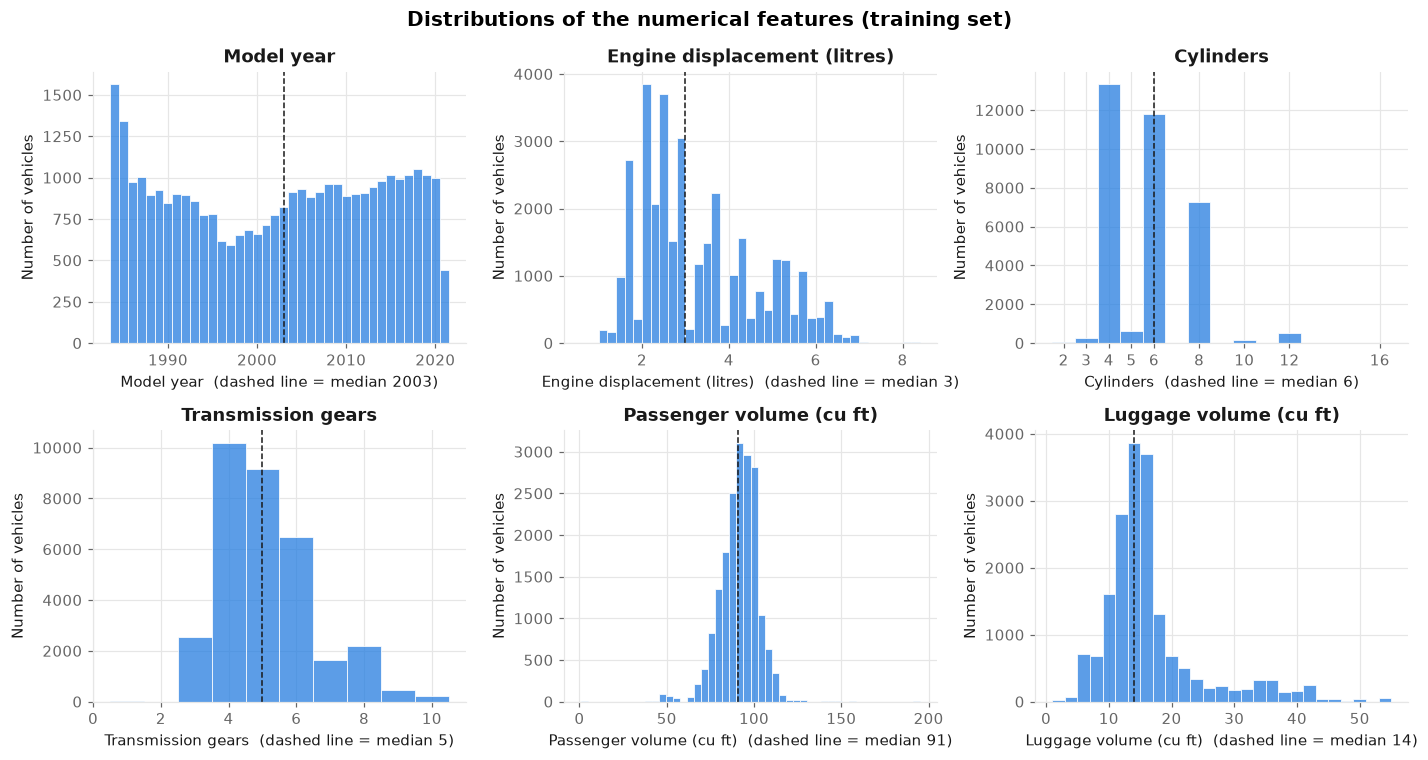

In [6]:
labels = {
    "year": "Model year", "displ": "Engine displacement (litres)", "cylinders": "Cylinders",
    "trans_speeds": "Transmission gears", "passenger_volume": "Passenger volume (cu ft)",
    "luggage_volume": "Luggage volume (cu ft)",
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, prep.NUMERIC_FEATURES):
    data = train[col].dropna()
    if col in ("year", "cylinders", "trans_speeds"):
        sns.histplot(data, ax=ax, color=BLUE, discrete=True, edgecolor="white", linewidth=0.5)
    else:
        width = {"displ": 0.2, "passenger_volume": 4, "luggage_volume": 2}[col]
        sns.histplot(data, ax=ax, color=BLUE, binwidth=width, edgecolor="white", linewidth=0.5)
    if col == "cylinders":
        ax.set_xticks([2, 3, 4, 5, 6, 8, 10, 12, 16])
    ax.axvline(data.median(), color=TEXT, linestyle="--", linewidth=1)
    ax.set_title(f"{labels[col]}")
    ax.set_xlabel(f"{labels[col]}  (dashed line = median {data.median():g})")
    ax.set_ylabel("Number of vehicles")
fig.suptitle("Distributions of the numerical features (training set)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "numeric_distributions")
plt.show()

**Observations:**

- **Engine displacement** is right-skewed. Most engines are 1.5 to 4.5 L, with a
  smaller group of large V8/V10/V12 engines up to 8.4 L.
- **Cylinders** is effectively categorical: 4, 6 and 8 make up about 95% of
  vehicles. Odd counts (3, 5) and very large engines (10, 12, 16) are rare.
- **Model year** covers every year from 1984 to 2021, so all eras are represented.
  Coverage is uneven: 1984 to 1985 have the most records, the late 1990s the fewest, and
  2021 is only partly covered (the dataset snapshot was taken during that year).
- **Transmission gears** shifts upward over time (3 to 4 gears in the 1980s, 8 to 10
  today). Section 5 shows it is strongly correlated with `year`.
- **Passenger volume** is roughly bell-shaped around 91 cu ft. **Luggage volume** is
  strongly right-skewed (skew 1.8), because a few wagons and hatchbacks have very
  large cargo areas.
- The features are on very different scales (years in the thousands, gears below 10),
  so **standard scaling is needed for Linear Regression**. Tree models do not need it.

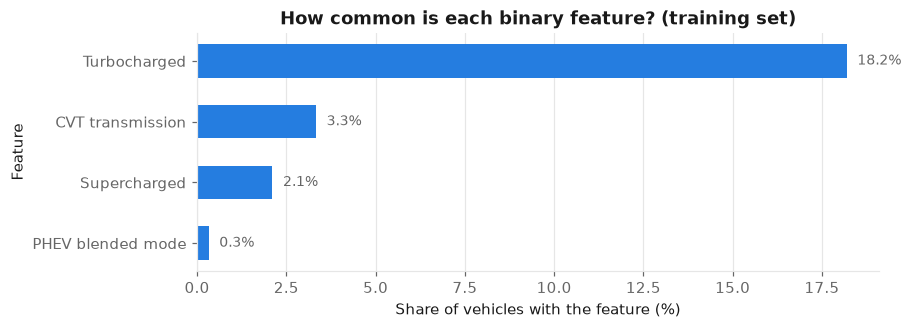

In [7]:
binary_share = train[prep.BINARY_FEATURES].mean().mul(100).sort_values()
binary_labels = {"turbo": "Turbocharged", "supercharger": "Supercharged",
                 "is_cvt": "CVT transmission", "phevBlended": "PHEV blended mode"}

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh([binary_labels[c] for c in binary_share.index], binary_share.values, color=BLUE, height=0.55)
for y, v in enumerate(binary_share.values):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", color=TEXT_2, fontsize=9)
ax.set_title("How common is each binary feature? (training set)")
ax.set_xlabel("Share of vehicles with the feature (%)")
ax.set_ylabel("Feature")
ax.grid(axis="y", visible=False)
save(fig, "binary_features")
plt.show()

**Observations:** 18% of vehicles are turbocharged, and only 2 to 3% are
supercharged or have a CVT. The `phevBlended` flag is almost always 0 (0.3%), so it
can only help for a handful of plug-in hybrids.

## 3. Categorical feature analysis

### 3.1 Cardinality

The number of distinct values (cardinality) decides how a categorical feature should
be encoded.

In [8]:
cardinality = pd.DataFrame({
    "unique_values": train[prep.CATEGORICAL_FEATURES].nunique(),
    "most_common": train[prep.CATEGORICAL_FEATURES].mode().iloc[0],
    "most_common_share_%": [
        train[c].value_counts(normalize=True).iloc[0] * 100 for c in prep.CATEGORICAL_FEATURES
    ],
    "values_seen_<20_times": [
        (train[c].value_counts() < prep.MIN_CATEGORY_FREQUENCY).sum() for c in prep.CATEGORICAL_FEATURES
    ],
}).sort_values("unique_values", ascending=False)
cardinality.round(1)

,unique_values,most_common,most_common_share_%,values_seen_<20_times
eng_dscr,497,Not specified,38.9,432
make,125,Chevrolet,9.6,65
trans_dscr,52,Not specified,64.6,29
trany,39,Automatic 4-spd,25.8,10
VClass,32,Compact Cars,14.0,3
fuelType,13,Regular,63.5,3
atvType,8,Conventional,91.4,2
drive,7,Front-Wheel Drive,35.3,0
fuelType2,5,Single fuel,95.9,2
fuelType1,5,Regular Gasoline,66.9,0


**Observations:**

- `eng_dscr` (about 500 values) and `make` (125 values) have **high cardinality with a
  long tail**: hundreds of values appear fewer than 20 times. One-hot encoding every
  value would create many almost-empty columns. This is why the pipeline groups rare
  values into a single "infrequent" category.
- `trans_type`, `startStop`, `drive` and `fuelType1` have only a few values each and
  are easy to one-hot encode.
- Some features are **dominated by one value**, e.g. `atvType` = Conventional (91%)
  and `fuelType2` = Single fuel. Their minority groups (hybrids, diesels) are small but
  matter a lot, as Section 6 shows.

### 3.2 Distribution of the main categorical features

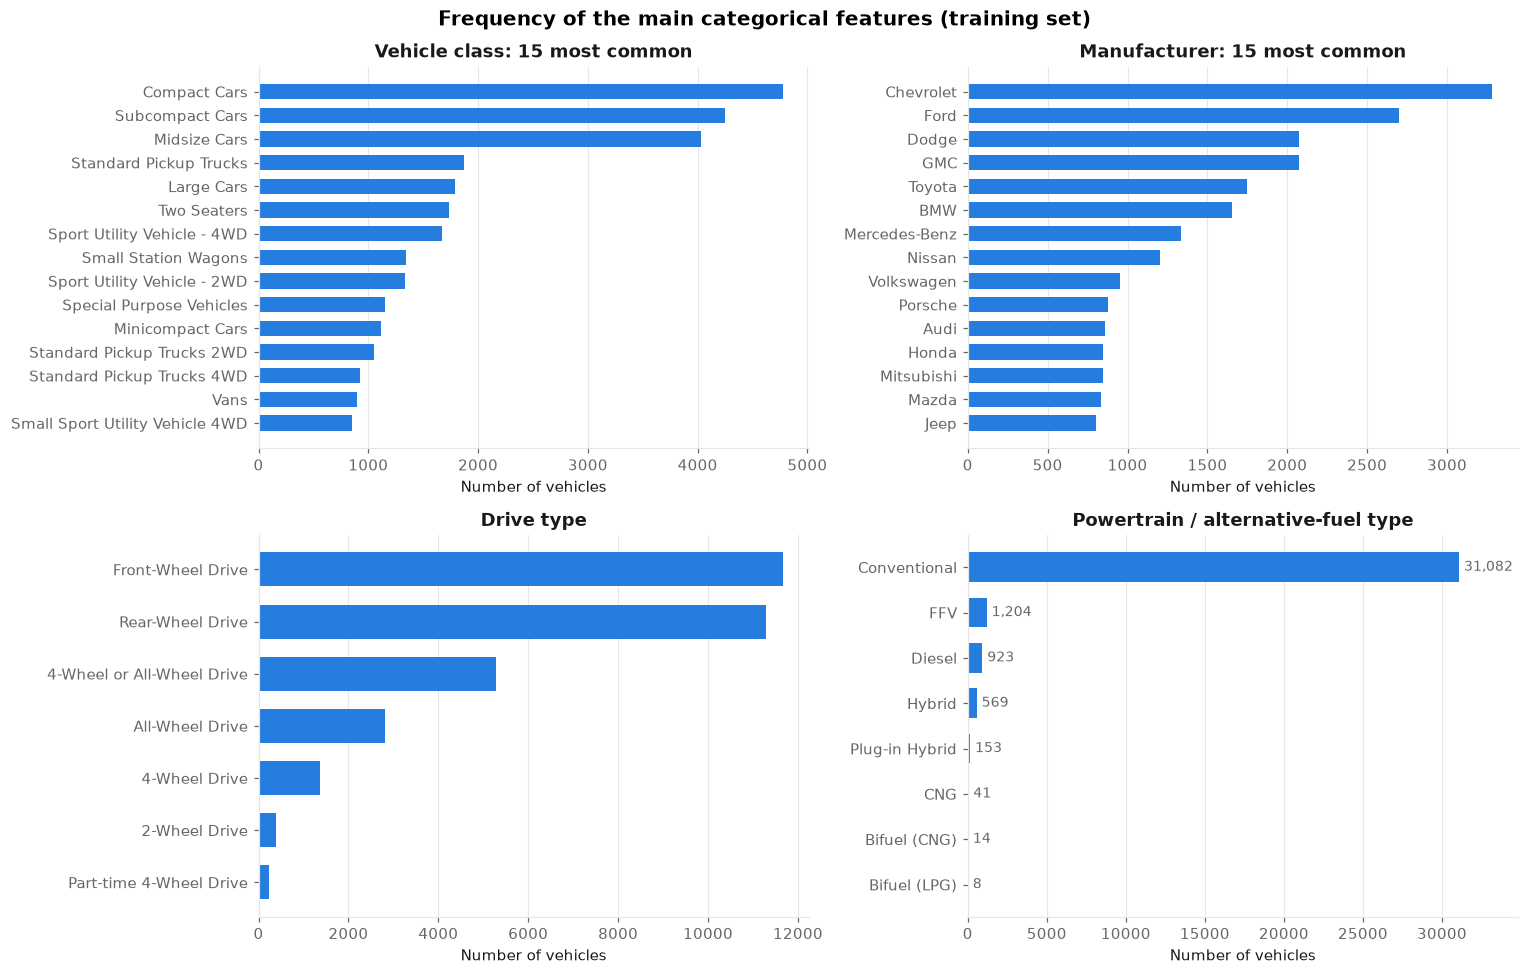

In [9]:
def count_bar(ax, series, title, xlabel, top=None, label_values=False):
    counts = series.value_counts()
    if top:
        counts = counts.head(top)
    counts = counts.iloc[::-1]
    ax.barh(counts.index.astype(str), counts.values, color=BLUE, height=0.65)
    if label_values:
        for y, v in enumerate(counts.values):
            ax.text(v + counts.max() * 0.01, y, f"{v:,}", va="center", color=TEXT_2, fontsize=9)
        ax.set_xlim(0, counts.max() * 1.12)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
count_bar(axes[0, 0], train["VClass"], "Vehicle class: 15 most common", "Number of vehicles", top=15)
count_bar(axes[0, 1], train["make"], "Manufacturer: 15 most common", "Number of vehicles", top=15)
count_bar(axes[1, 0], train["drive"], "Drive type", "Number of vehicles")
count_bar(axes[1, 1], train["atvType"], "Powertrain / alternative-fuel type", "Number of vehicles",
          label_values=True)
for ax in axes.flat:
    ax.set_ylabel("")
fig.suptitle("Frequency of the main categorical features (training set)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "categorical_counts")
plt.show()

**Observations:**

- **Vehicle class:** compact, subcompact and midsize cars are the largest groups,
  followed by pickups and SUVs. The data covers the whole market, not just cars.
- **Manufacturer:** US brands (Chevrolet, Ford, Dodge, GMC) contribute the most models.
  The top 10 makes cover about half of all vehicles.
- **Drive type:** front- and rear-wheel drive dominate. Note that
  **"4-Wheel or All-Wheel Drive" was used until 2009, and "All-Wheel Drive" /
  "Part-time 4-Wheel Drive" only from 2009/2010**. This is a change in how the data was
  labelled over time, not a real difference between vehicles. The model can partly
  compensate through `year`, but it is worth remembering when interpreting importances.
- **Powertrain:** about 91% conventional petrol (the counts are labelled because the small groups are barely visible). Hybrids, plug-in hybrids and diesels
  are only about 5% combined, but they have very different fuel economy.

In [10]:
print("Years in which each drive label is used:")
train.groupby("drive")["year"].agg(first_year="min", last_year="max", vehicles="count")

Years in which each drive label is used:


,first_year,last_year,vehicles
drive,,,
2-Wheel Drive,1984,2006,388
4-Wheel Drive,1985,2021,1374
4-Wheel or All-Wheel Drive,1984,2009,5286
All-Wheel Drive,2009,2021,2815
Front-Wheel Drive,1985,2021,11658
Part-time 4-Wheel Drive,2010,2021,240
Rear-Wheel Drive,1984,2021,11287


## 4. Target variable: `comb08`

In [11]:
target_stats = y_train.describe()
target_stats["skew"] = y_train.skew()
target_stats["skew of log(comb08)"] = np.log(y_train).skew()
target_stats.round(2)

count                  33994.00
mean                      20.38
std                        5.33
min                        7.00
25%                       17.00
50%                       20.00
75%                       23.00
max                       58.00
skew                       1.15
skew of log(comb08)        0.09
Name: comb08, dtype: float64

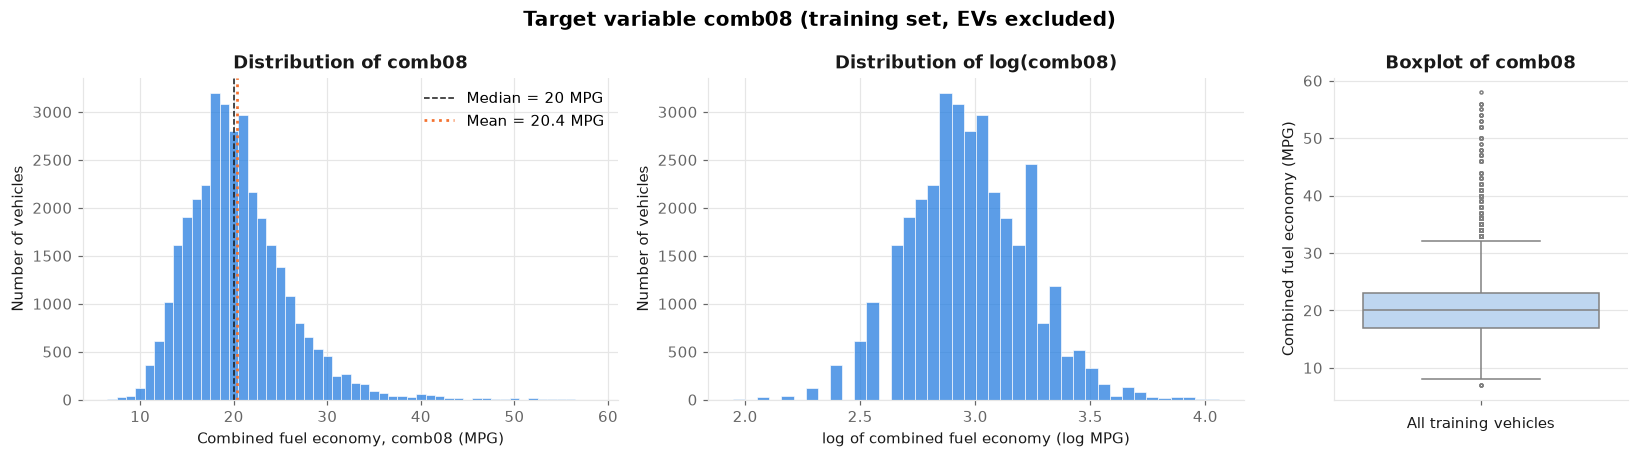

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2, 2, 1.1]})

sns.histplot(y_train, discrete=True, color=BLUE, edgecolor="white", linewidth=0.4, ax=axes[0])
axes[0].axvline(y_train.median(), color=TEXT, linestyle="--", linewidth=1,
                label=f"Median = {y_train.median():g} MPG")
axes[0].axvline(y_train.mean(), color=SERIES[1], linestyle=":", linewidth=1.8,
                label=f"Mean = {y_train.mean():.1f} MPG")
axes[0].legend(loc="upper right")
axes[0].set_title("Distribution of comb08")
axes[0].set_xlabel("Combined fuel economy, comb08 (MPG)")
axes[0].set_ylabel("Number of vehicles")

sns.histplot(np.log(y_train), bins=40, color=BLUE, edgecolor="white", linewidth=0.4, ax=axes[1])
axes[1].set_title("Distribution of log(comb08)")
axes[1].set_xlabel("log of combined fuel economy (log MPG)")
axes[1].set_ylabel("Number of vehicles")

sns.boxplot(y=y_train, color="#b6d5f8", ax=axes[2], fliersize=2, linewidth=1)
axes[2].set_title("Boxplot of comb08")
axes[2].set_ylabel("Combined fuel economy (MPG)")
axes[2].set_xlabel("All training vehicles")

fig.suptitle("Target variable comb08 (training set, EVs excluded)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "target_distribution")
plt.show()

**Observations:**

- Most vehicles achieve **15 to 25 MPG**: median 20, mean 20.4 and standard deviation
  5.3.
- The distribution is **right-skewed** (skew about 1.15), with a long tail of
  efficient vehicles up to 58 MPG (hybrids). The mean is pulled above the median.
- Taking the **logarithm makes it almost symmetric** (skew about 0.1). A log-transformed
  target is worth testing for Linear Regression, which works best when errors are
  symmetric. Tree models do not need it.
- All values are whole numbers (EPA rounds `comb08`), and there are no zeros or
  negative values.

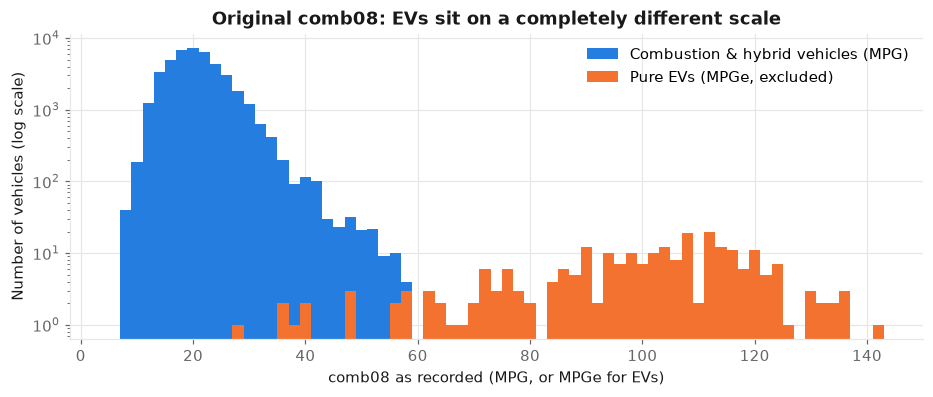

In [13]:
# Context only: how the original target looked before EVs were removed (original dataset).
fig, ax = plt.subplots(figsize=(10, 3.6))
is_ev = prep.is_pure_electric(raw)
bins = np.arange(5, 145, 2)
ax.hist(raw.loc[~is_ev, TARGET], bins=bins, color=SERIES[0], label="Combustion & hybrid vehicles (MPG)")
ax.hist(raw.loc[is_ev, TARGET], bins=bins, color=SERIES[1], label="Pure EVs (MPGe, excluded)")
ax.set_yscale("log")
ax.set_title("Original comb08: EVs sit on a completely different scale")
ax.set_xlabel("comb08 as recorded (MPG, or MPGe for EVs)")
ax.set_ylabel("Number of vehicles (log scale)")
ax.legend(loc="upper right")
save(fig, "target_ev_context")
plt.show()

**Observation:** this chart uses the original dataset and repeats the reason EVs were
excluded in notebook 02. EV values (28 to 141 MPGe) barely overlap with combustion
vehicles. A log scale is used for the counts because there are only 241 EVs.

## 5. Correlation analysis

Correlation measures how strongly two numbers move together, from −1 to +1:

- **Pearson** measures *linear* relationships.
- **Spearman** uses ranks, so it also captures relationships that are *monotonic but
  curved*.

Only legitimate model features are included. Leakage columns are excluded.

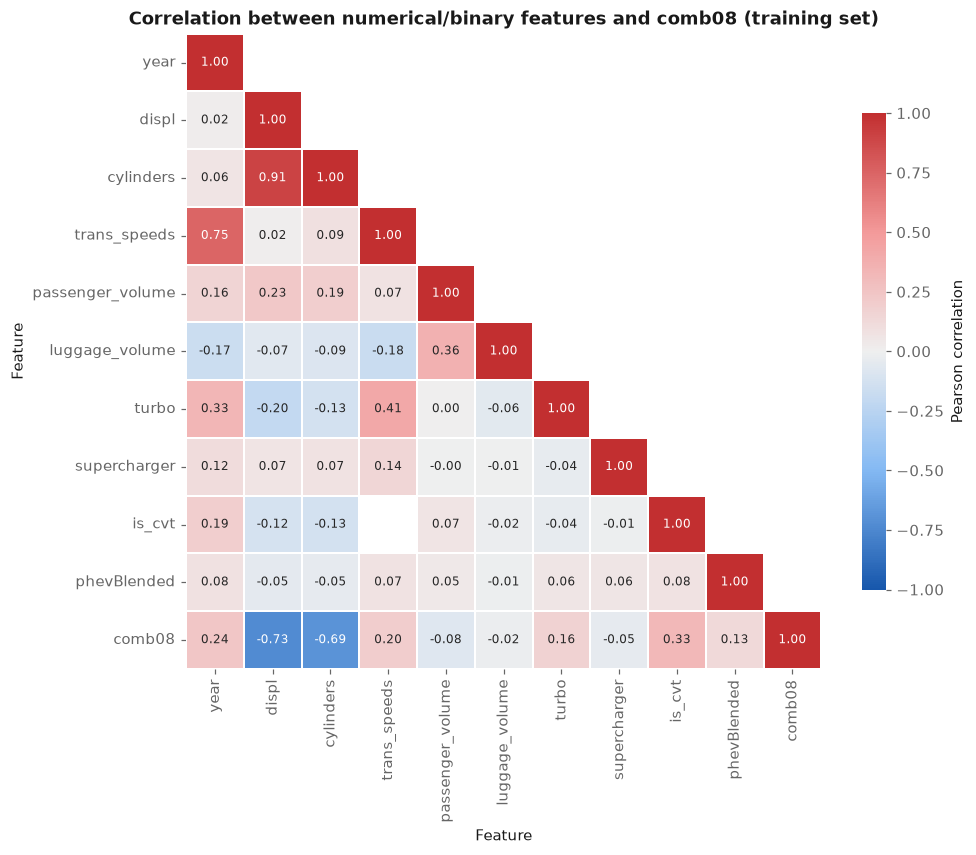

In [14]:
corr_cols = prep.NUMERIC_FEATURES + prep.BINARY_FEATURES + [TARGET]
pearson = train[corr_cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor="white", square=True,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.75}, ax=ax)
ax.set_title("Correlation between numerical/binary features and comb08 (training set)")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
ax.grid(False)
save(fig, "correlation_heatmap")
plt.show()

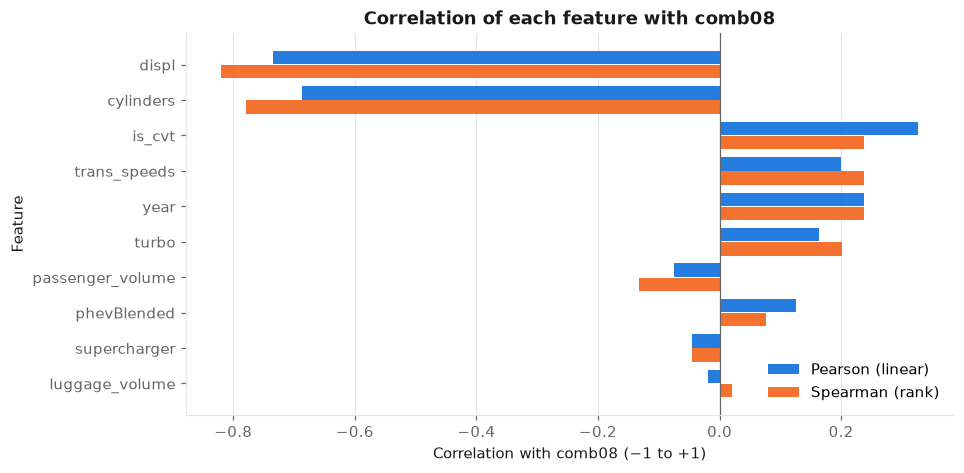

,pearson,spearman
displ,-0.734,-0.820
cylinders,-0.688,-0.779
is_cvt,0.327,0.238
trans_speeds,0.200,0.238
year,0.237,0.237
turbo,0.164,0.202
passenger_volume,-0.075,-0.133
phevBlended,0.125,0.077
supercharger,-0.046,-0.046
luggage_volume,-0.018,0.021


In [15]:
target_corr = pd.DataFrame({
    "pearson": train[corr_cols].corr("pearson")[TARGET],
    "spearman": train[corr_cols].corr("spearman")[TARGET],
}).drop(TARGET).sort_values("spearman", key=abs, ascending=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(target_corr))
ax.barh(y + 0.2, target_corr["pearson"], height=0.38, color=SERIES[0], label="Pearson (linear)")
ax.barh(y - 0.2, target_corr["spearman"], height=0.38, color=SERIES[1], label="Spearman (rank)")
ax.set_yticks(y, target_corr.index)
ax.axvline(0, color=TEXT_2, linewidth=0.8)
ax.set_title("Correlation of each feature with comb08")
ax.set_xlabel("Correlation with comb08 (−1 to +1)")
ax.set_ylabel("Feature")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "target_correlations")
plt.show()
target_corr.sort_values("spearman", key=abs, ascending=False).round(3)

**Observations:**

- **Engine size is the dominant driver.** `displ` (Pearson −0.73, Spearman −0.82) and
  `cylinders` (−0.69 / −0.78) are by far the strongest predictors: bigger engines mean
  lower MPG.
- For these two, **Spearman is clearly stronger than Pearson**. The relationship is
  consistent but **curved**, not a straight line (Section 6.1). A plain linear model
  will miss part of it, while tree-based models capture curves naturally.
- `is_cvt` (+0.33), `year` (+0.24), `trans_speeds` (+0.20/+0.24) and `turbo`
  (+0.16/+0.20) have moderate positive relationships: newer technology means better
  economy.
- The interior volumes are only weakly correlated with MPG.
- The blank `is_cvt` / `trans_speeds` cell is expected: CVTs have no gear count, so
  `trans_speeds` is always missing when `is_cvt` = 1 and no correlation can be computed.
- **Multicollinearity:** `displ` and `cylinders` are correlated at **0.91**, and `year`
  and `trans_speeds` at **0.75**. This barely affects tree models, but it makes Linear
  Regression coefficients unstable and hard to interpret individually. Their combined
  effect on predictions is still fine.

## 6. Relationships between key features and `comb08`

### 6.1 Engine displacement

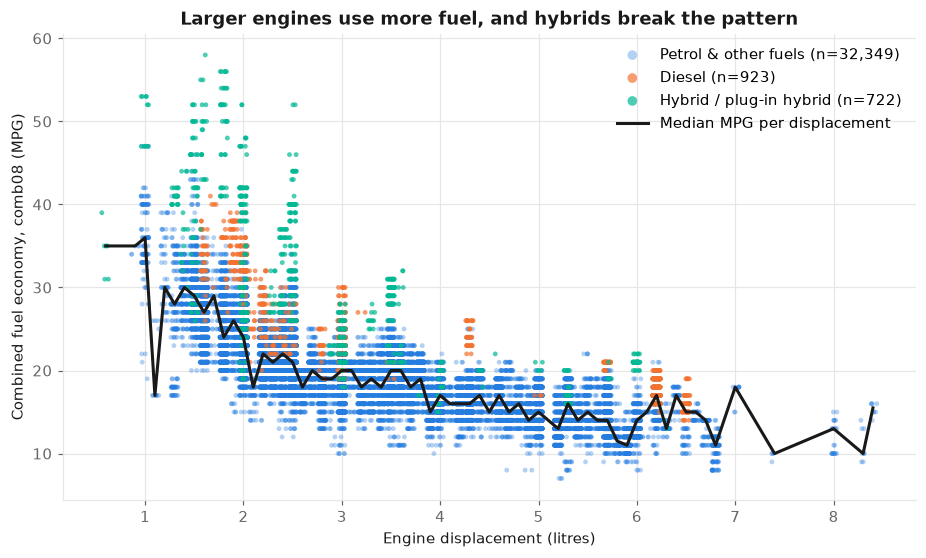

In [16]:
group = np.select(
    [train["atvType"].isin(["Hybrid", "Plug-in Hybrid"]), train["atvType"].eq("Diesel")],
    ["Hybrid / plug-in hybrid", "Diesel"], default="Petrol & other fuels")
order = ["Petrol & other fuels", "Diesel", "Hybrid / plug-in hybrid"]

fig, ax = plt.subplots(figsize=(10, 5.5))
rng = np.random.default_rng(prep.RANDOM_STATE)
jitter = rng.uniform(-0.04, 0.04, len(train))            # small jitter: displ is rounded to 0.1 L
for colour, name in zip(SERIES, order):
    sel = group == name
    ax.scatter(train.loc[sel, "displ"] + jitter[sel], train.loc[sel, TARGET], s=10,
               alpha=0.35 if name == order[0] else 0.7, color=colour, edgecolors="none",
               label=f"{name} (n={sel.sum():,})")
medians = train.groupby(train["displ"].round(1))[TARGET].median()
ax.plot(medians.index, medians.values, color=TEXT, linewidth=2, label="Median MPG per displacement")
ax.set_title("Larger engines use more fuel, and hybrids break the pattern")
ax.set_xlabel("Engine displacement (litres)")
ax.set_ylabel("Combined fuel economy, comb08 (MPG)")
ax.legend(loc="upper right", markerscale=2)
save(fig, "displ_vs_comb08")
plt.show()

**Observations:**

- MPG **falls steeply** from about 30 MPG for engines up to 1.5 L to about 20 MPG at
  3 L, then **levels off** for large engines (about 15 MPG above 5 L). This curved
  shape is why Spearman > Pearson. MPG is closer to proportional to *1 / displacement*
  than to displacement itself.
- At the same displacement, MPG still varies a lot (e.g. 2.0 L engines range from
  about 15 to 50 MPG). **Engine size alone is not enough.** Vehicle class, drive type and
  powertrain explain the rest.
- **Hybrids (green) lie far above** the petrol trend at every engine size, and
  **diesels (orange) sit slightly above** it. Without `atvType`, a model would
  badly underestimate hybrids.

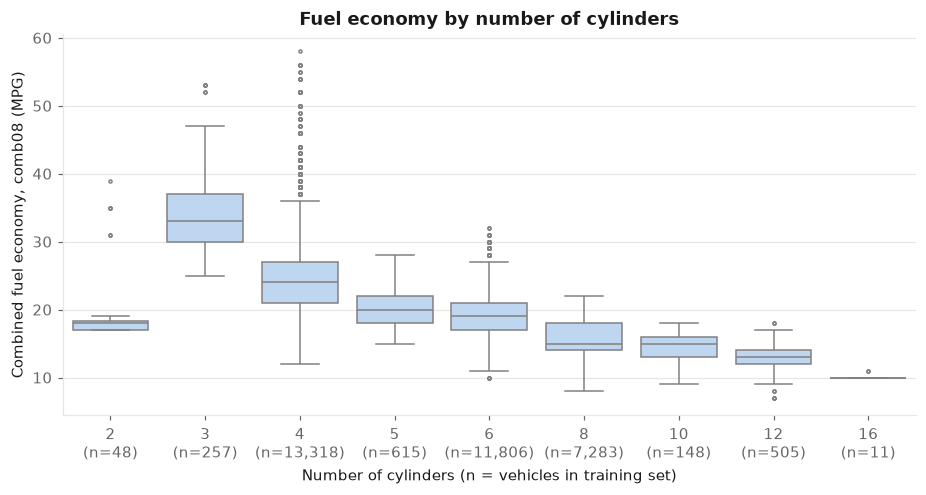

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cyl_order = sorted(train["cylinders"].dropna().unique())
sns.boxplot(data=train, x="cylinders", y=TARGET, order=cyl_order, color="#b6d5f8",
            fliersize=2, linewidth=1, ax=ax, native_scale=False)
counts = train["cylinders"].value_counts()
ax.set_xticks(range(len(cyl_order)), [f"{int(c)}\n(n={counts[c]:,})" for c in cyl_order])
ax.set_title("Fuel economy by number of cylinders")
ax.set_xlabel("Number of cylinders (n = vehicles in training set)")
ax.set_ylabel("Combined fuel economy, comb08 (MPG)")
save(fig, "cylinders_vs_comb08")
plt.show()

**Observations:** median MPG falls steadily from 3 to 16 cylinders (3-cylinder
microcars about 34 MPG, 4-cylinder about 24, 6 about 19, 8 about 15, 12 about 13).
The 2-cylinder group (48 rows, rotary engines) and the 16-cylinder group (11 rows,
Bugatti) are tiny, so their estimates are less reliable. The spread inside the 4- and
6-cylinder boxes is wide: that is where hybrids and modern turbo engines sit.

### 6.2 Vehicle class, drive type and powertrain

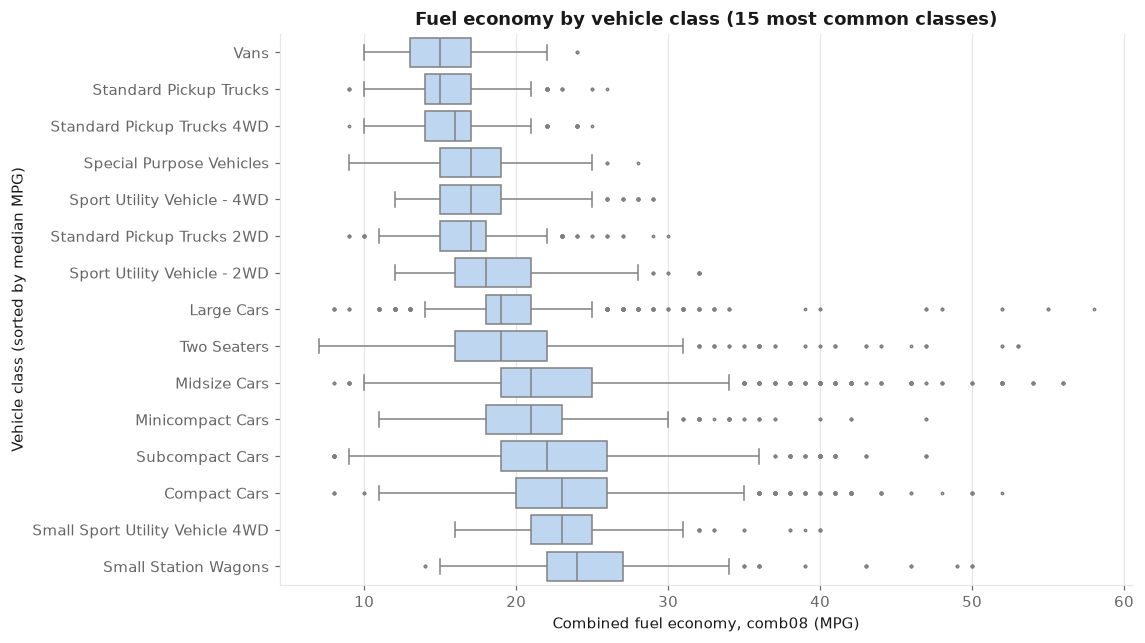

In [18]:
top_classes = train["VClass"].value_counts().head(15).index
cls = train[train["VClass"].isin(top_classes)]
cls_order = cls.groupby("VClass")[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.boxplot(data=cls, y="VClass", x=TARGET, order=cls_order, color="#b6d5f8",
            fliersize=1.5, linewidth=1, ax=ax)
ax.set_title("Fuel economy by vehicle class (15 most common classes)")
ax.set_xlabel("Combined fuel economy, comb08 (MPG)")
ax.set_ylabel("Vehicle class (sorted by median MPG)")
save(fig, "vclass_vs_comb08")
plt.show()

**Observations:** there is a clear ordering by size and purpose. **Vans, pickups and
4WD SUVs** have the lowest MPG (medians about 15 to 17), while **small station wagons,
small 4WD SUVs, compact and subcompact cars** have the highest (about 22 to 24). The
long right tails in the car classes (up to 58 MPG) are hybrids. Vehicle class captures
weight and aerodynamics, which are not otherwise in the dataset, so it is an important
feature.

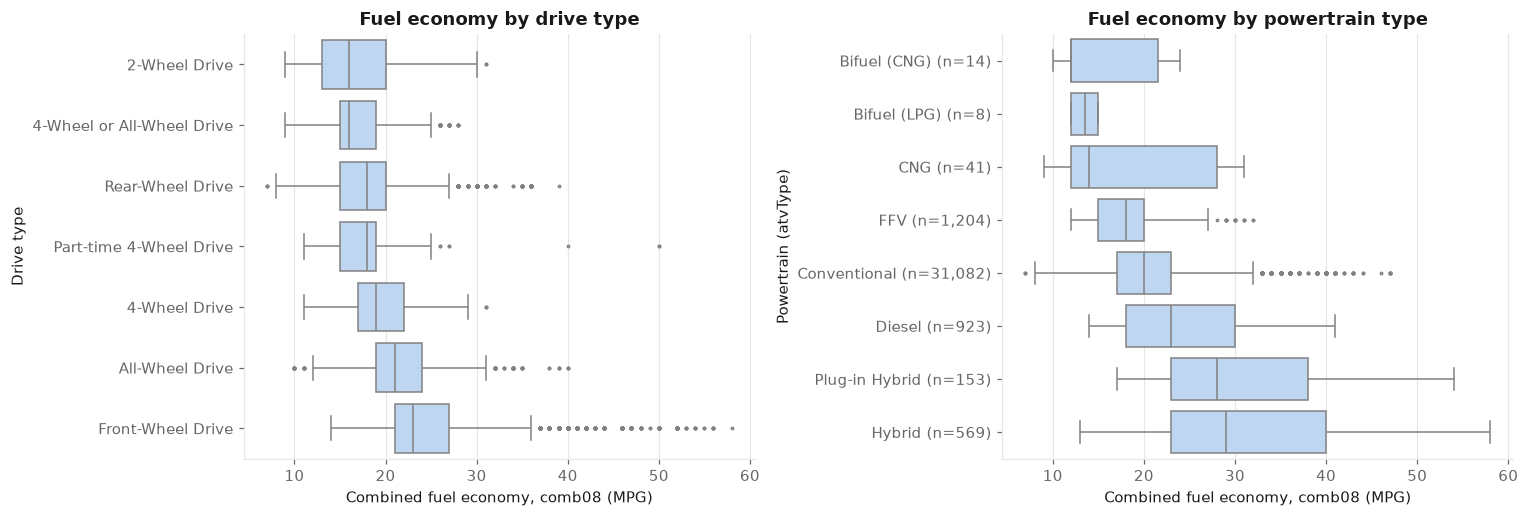

,count,mean,median,min,max
atvType,,,,,
Bifuel (CNG),14,16.0,12.0,10,24
Bifuel (LPG),8,13.5,13.5,12,15
CNG,41,18.0,14.0,9,31
FFV,1204,18.0,18.0,12,32
Conventional,31082,20.1,20.0,7,47
Diesel,923,24.0,23.0,14,41
Plug-in Hybrid,153,30.7,28.0,17,54
Hybrid,569,31.9,29.0,13,58


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

drive_order = train.groupby("drive")[TARGET].median().sort_values().index
sns.boxplot(data=train, y="drive", x=TARGET, order=drive_order, color="#b6d5f8",
            fliersize=1.5, linewidth=1, ax=axes[0])
axes[0].set_title("Fuel economy by drive type")
axes[0].set_xlabel("Combined fuel economy, comb08 (MPG)")
axes[0].set_ylabel("Drive type")

atv_order = train.groupby("atvType")[TARGET].median().sort_values().index
sns.boxplot(data=train, y="atvType", x=TARGET, order=atv_order, color="#b6d5f8",
            fliersize=1.5, linewidth=1, ax=axes[1])
atv_counts = train["atvType"].value_counts()
axes[1].set_yticks(range(len(atv_order)), [f"{a} (n={atv_counts[a]:,})" for a in atv_order])
axes[1].set_title("Fuel economy by powertrain type")
axes[1].set_xlabel("Combined fuel economy, comb08 (MPG)")
axes[1].set_ylabel("Powertrain (atvType)")

fig.tight_layout()
save(fig, "drive_powertrain_vs_comb08")
plt.show()
train.groupby("atvType")[TARGET].agg(["count", "mean", "median", "min", "max"]).sort_values("median").round(1)

**Observations:**

- **Front-wheel drive** has the best median MPG (about 23). Rear-wheel, 2WD, 4WD and
  "4-Wheel or All-Wheel Drive" are lower (medians about 16 to 19), because those
  layouts tend to be used for heavier and more powerful vehicles.
- "All-Wheel Drive" (median about 21) scores clearly better than the older
  "4-Wheel or All-Wheel Drive" label (about 16). Part of this gap is the **labelling
  change**: the newer label only covers 2009+ vehicles, which are more efficient overall.
- **Hybrids and plug-in hybrids** have median MPG of about 28 to 29, **diesels** about
  23, conventional petrol about 20, and **flex-fuel / natural-gas** vehicles less.
  Powertrain type is a strong signal, even though few vehicles fall outside the
  conventional group.
- The CNG and bi-fuel groups have very few vehicles (8 to 41), so the model has little
  data to learn their patterns from.

### 6.3 Change over time

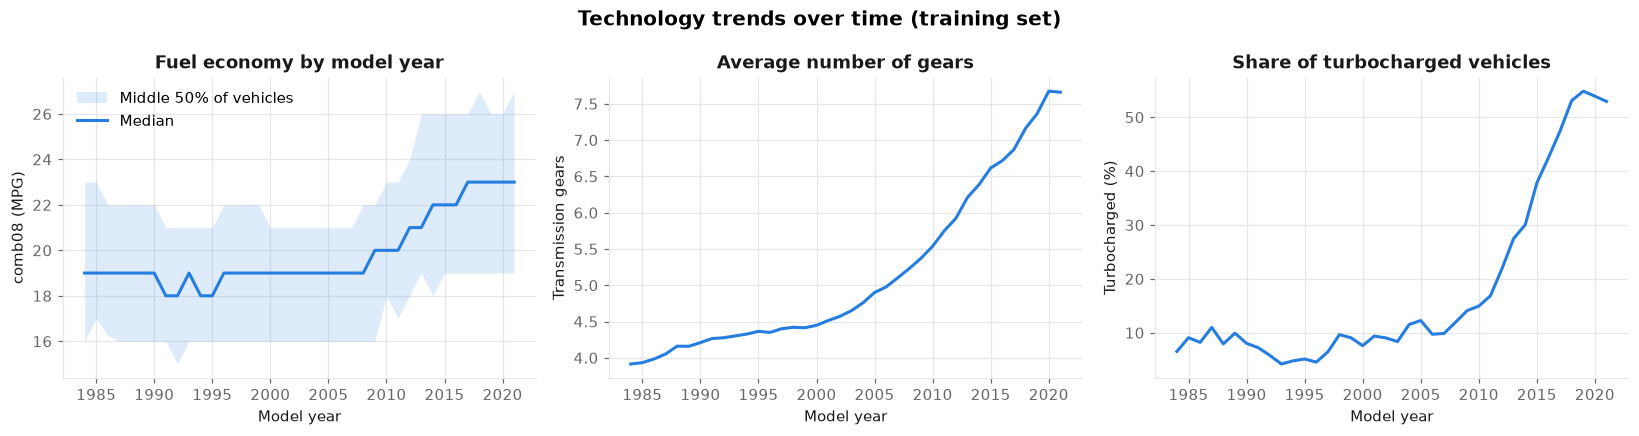

In [20]:
by_year = train.groupby("year").agg(
    median_mpg=(TARGET, "median"), q25=(TARGET, lambda s: s.quantile(0.25)),
    q75=(TARGET, lambda s: s.quantile(0.75)), turbo_share=("turbo", "mean"),
    mean_gears=("trans_speeds", "mean"), mean_displ=("displ", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
axes[0].fill_between(by_year.index, by_year["q25"], by_year["q75"], color=BLUE, alpha=0.15,
                     linewidth=0, label="Middle 50% of vehicles")
axes[0].plot(by_year.index, by_year["median_mpg"], color=BLUE, linewidth=2, label="Median")
axes[0].set_title("Fuel economy by model year")
axes[0].set_ylabel("comb08 (MPG)")
axes[0].legend(loc="upper left")

axes[1].plot(by_year.index, by_year["mean_gears"], color=BLUE, linewidth=2)
axes[1].set_title("Average number of gears")
axes[1].set_ylabel("Transmission gears")

axes[2].plot(by_year.index, by_year["turbo_share"] * 100, color=BLUE, linewidth=2)
axes[2].set_title("Share of turbocharged vehicles")
axes[2].set_ylabel("Turbocharged (%)")

for ax in axes:
    ax.set_xlabel("Model year")
fig.suptitle("Technology trends over time (training set)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "trends_by_year")
plt.show()

**Observations:**

- Median fuel economy stayed **flat at about 18 to 19 MPG from 1984 until about
  2008**, then **rose steadily to about 23 MPG by 2017 to 2021**. This matches the tightening of
  US fuel-economy (CAFE) standards.
- Over the same period, transmissions went from about 4 to about 8 gears, and turbocharging
  went from under 10% to over 50% of new vehicles. These technologies explain much
  of the gain, and they are why `year` is correlated with `trans_speeds` (0.75).
- The relationship with year is **not linear** (flat, then rising). Trees capture this
  directly, while a linear model only fits the average slope.

### 6.4 Transmission and start-stop

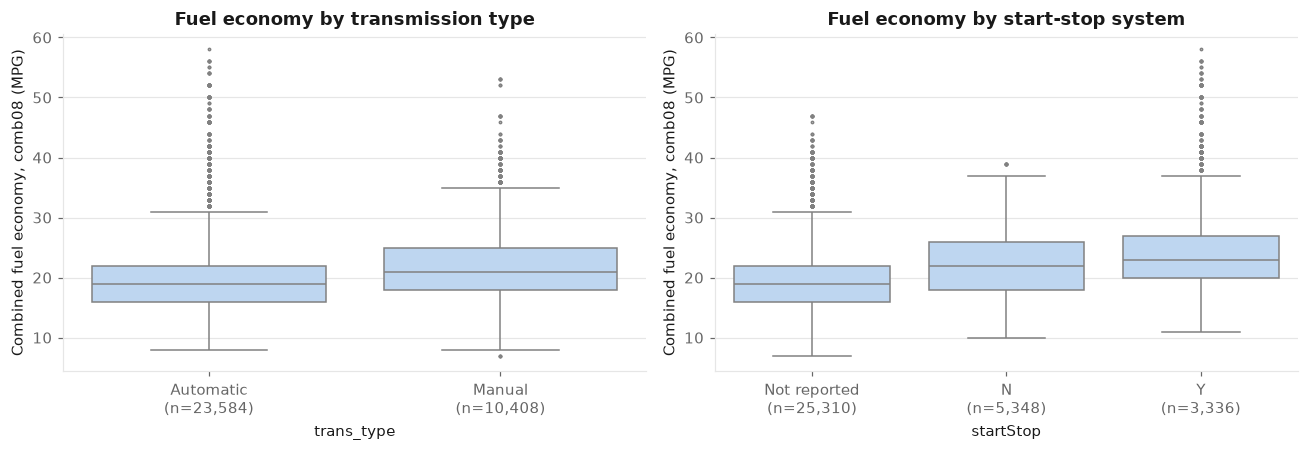

Median model year by startStop value:
startStop
N               2016.0
Not reported    1997.0
Y               2018.0
Name: year, dtype: float64


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title in [(axes[0], "trans_type", "Fuel economy by transmission type"),
                       (axes[1], "startStop", "Fuel economy by start-stop system")]:
    order_ = train.groupby(col)[TARGET].median().sort_values().index
    sns.boxplot(data=train, x=col, y=TARGET, order=order_, color="#b6d5f8", fliersize=1.5,
                linewidth=1, ax=ax)
    n = train[col].value_counts()
    ax.set_xticks(range(len(order_)), [f"{v}\n(n={n[v]:,})" for v in order_])
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Combined fuel economy, comb08 (MPG)")
fig.tight_layout()
save(fig, "transmission_startstop_vs_comb08")
plt.show()
print("Median model year by startStop value:")
print(train.groupby("startStop")["year"].median())

**Observations:**

- Manual transmissions have a slightly higher median MPG than automatics. This is
  partly because manuals are more common in small cars, so the effect is confounded
  with vehicle size.
- Vehicles **with start-stop** have the highest MPG, and "Not reported" the lowest. But
  "Not reported" is mostly older vehicles (the field was only recorded from the 2010s),
  so this feature partly encodes **model year**. It is kept, but not interpreted as a
  pure technology effect.

## 7. Outlier investigation

### 7.1 Outliers in the numerical features (IQR rule)

A value is flagged if it lies more than 1.5 × IQR below the 25th or above the 75th
percentile.

In [22]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(), q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in prep.NUMERIC_FEATURES + [TARGET]:
    n, lo, hi = iqr_outliers(train[col].dropna())
    rows.append({"feature": col, "outliers": n, "outlier_%": n / train[col].notna().sum() * 100,
                 "lower_bound": lo, "upper_bound": hi,
                 "min": train[col].min(), "max": train[col].max()})
pd.DataFrame(rows).set_index("feature").round(2)

,outliers,outlier_%,lower_bound,upper_bound,min,max
feature,,,,,,
year,0,0.00,1962.00,2042.00,1984.0,2021.0
displ,39,0.11,-0.95,7.45,0.6,8.4
cylinders,664,1.95,1.00,9.00,2.0,16.0
trans_speeds,222,0.68,1.00,9.00,1.0,10.0
passenger_volume,371,2.01,65.50,117.50,1.0,195.0
luggage_volume,2222,12.05,4.50,24.50,1.0,55.0
comb08,861,2.53,8.00,32.00,7.0,58.0


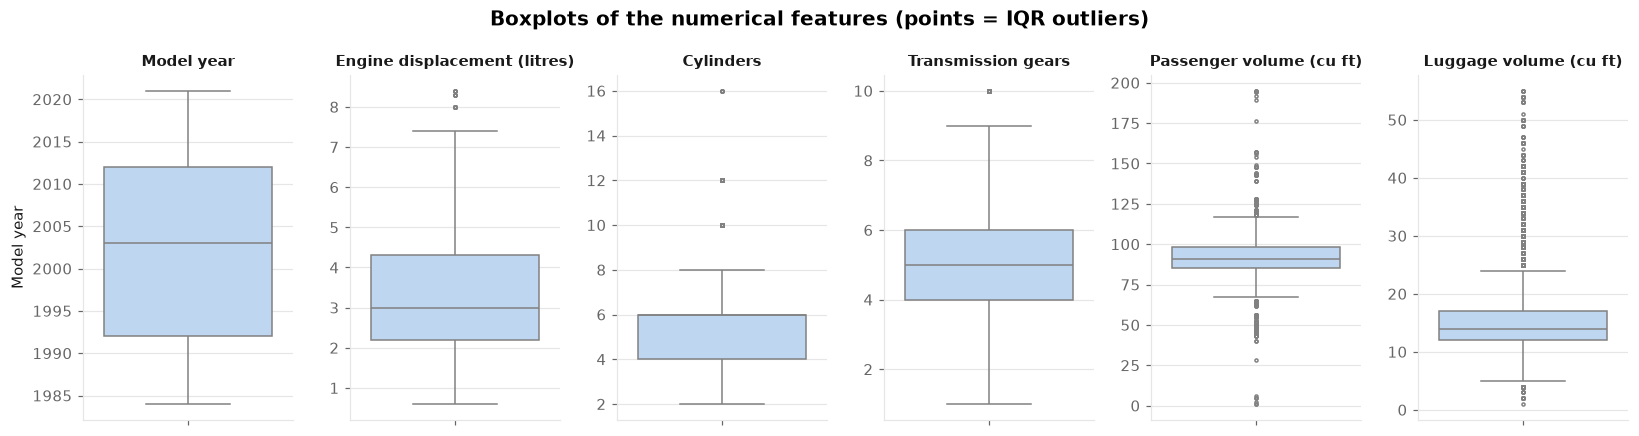

In [23]:
fig, axes = plt.subplots(1, 6, figsize=(15, 4))
for ax, col in zip(axes, prep.NUMERIC_FEATURES):
    sns.boxplot(y=train[col], color="#b6d5f8", fliersize=2, linewidth=1, ax=ax)
    ax.set_title(labels[col], fontsize=10)
    ax.set_ylabel(labels[col] if col == "year" else "")
    ax.set_xlabel("")
fig.suptitle("Boxplots of the numerical features (points = IQR outliers)", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "numeric_boxplots")
plt.show()

**Observations:** almost all flagged values are **real vehicles**: 8.4 L engines
(Dodge Viper), 10 to 16 cylinders (Lamborghini, Bugatti), 9 to 10-speed modern automatics,
and large luggage areas (the 12% luggage "outliers" are mostly station wagons). They are
physically plausible and are kept.

The **low end of the volume columns** is different. Let us look at it directly.

In [24]:
implausible = train["passenger_volume"] < 40
print(f"Passenger volume below 40 cu ft: {implausible.sum()} training rows")
train.loc[implausible, ["year", "make", "VClass", "passenger_volume", "luggage_volume", TARGET]] \
    .sort_values("passenger_volume")

Passenger volume below 40 cu ft: 7 training rows


,year,make,VClass,passenger_volume,luggage_volume,comb08
8307,1984,Bitter Gmbh and Co. Kg,Midsize Cars,1.0,16.0,14
30464,1984,Bitter Gmbh and Co. Kg,Midsize Cars,1.0,16.0,13
6120,1991,Porsche,Midsize Cars,2.0,2.0,15
16791,1991,Mercedes-Benz,Midsize Cars,5.0,4.0,15
17345,1991,Mercedes-Benz,Midsize Cars,5.0,5.0,17
15940,1991,Mercedes-Benz,Large Cars,6.0,6.0,15
17497,1984,Import Foreign Auto Sales Inc,Small Pickup Trucks 4WD,28.0,9.0,19


**Data-quality finding:** a few midsize and large cars from 1984 and 1991 are recorded with
**1 to 6 cu ft** of passenger space. That is impossible (a small two-seater has about
45 to 50 cu ft), so these are **data-entry errors**. They affect only 6 training rows, so
their impact is very small, and tree models are not affected by extreme input values.
**Recommendation:** in a later revision of `src/preprocessing.py`, treat passenger volumes
below 40 cu ft as missing, the same way `0` is already handled. Linear Regression can be
sensitive to extreme inputs, so these points should also be checked in the residuals
after training.

### 7.2 Outliers in the target

In [25]:
n_out, lo, hi = iqr_outliers(y_train)
high = train[TARGET] > hi
print(f"IQR bounds for comb08: [{lo}, {hi}]  ->  {n_out} outliers ({n_out / len(train) * 100:.1f}%)")
print("\nHigh comb08 outliers by powertrain:")
print(train.loc[high, "atvType"].value_counts().to_string())
print("\nConventional high-MPG outliers: displacement and cylinders")
print(train.loc[high & train["atvType"].eq("Conventional"), ["displ", "cylinders", "year"]].describe().round(1))

IQR bounds for comb08: [8.0, 32.0]  ->  861 outliers (2.5%)

High comb08 outliers by powertrain:
atvType
Conventional      423
Hybrid            231
Diesel            152
Plug-in Hybrid     52

Conventional high-MPG outliers: displacement and cylinders
       displ  cylinders    year
count  423.0      423.0   423.0
mean     1.4        3.7  2004.0
std      0.3        0.5    14.0
min      0.9        3.0  1984.0
25%      1.0        3.0  1990.0
50%      1.5        4.0  2010.0
75%      1.5        4.0  2018.0
max      2.5        4.0  2021.0


**Observations:** about 2.5% of training vehicles are above the IQR upper bound of
32 MPG. About half are hybrids, plug-in hybrids and diesels. The conventional ones are
**very small engines** (median 1.5 L, 3 to 4 cylinders), such as the Honda Civic HF/VX,
Geo Metro and Toyota Yaris. These are exactly the vehicles a fuel-economy model must
handle well, so the outliers are kept.

### 7.3 "Unusual for its engine size"

A more useful question is which vehicles are unusual **given their engine size**. We
compare each vehicle's MPG with the median for its displacement band, using a robust
score (distance from the median divided by the IQR within that band).

In [26]:
band = pd.cut(train["displ"], np.arange(0.5, 9.0, 0.5))
grp = train.groupby(band, observed=True)[TARGET]
band_median = grp.transform("median")
band_iqr = grp.transform(lambda s: s.quantile(0.75) - s.quantile(0.25)).replace(0, 1)
robust_z = (train[TARGET] - band_median) / band_iqr
unusual = robust_z.abs() > 3

print(f"Vehicles more than 3 IQRs from their displacement band median: {unusual.sum()} "
      f"({unusual.mean() * 100:.1f}%)")
print("\nBy powertrain:")
print(train.loc[unusual, "atvType"].value_counts().to_string())

Vehicles more than 3 IQRs from their displacement band median: 314 (0.9%)

By powertrain:
atvType
Hybrid            197
Diesel             68
Plug-in Hybrid     35
Conventional       14


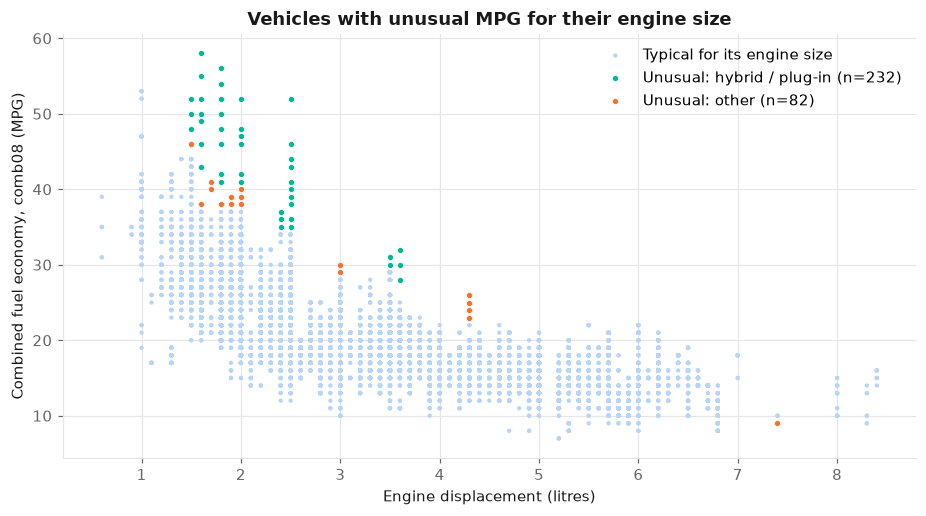

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(train.loc[~unusual, "displ"], train.loc[~unusual, TARGET], s=8, color="#b6d5f8",
           edgecolors="none", label="Typical for its engine size")
hyb = unusual & group.__eq__("Hybrid / plug-in hybrid")
oth = unusual & ~hyb
ax.scatter(train.loc[hyb, "displ"], train.loc[hyb, TARGET], s=16, color=SERIES[2],
           edgecolors="white", linewidths=0.5, label=f"Unusual: hybrid / plug-in (n={hyb.sum()})")
ax.scatter(train.loc[oth, "displ"], train.loc[oth, TARGET], s=16, color=SERIES[1],
           edgecolors="white", linewidths=0.5, label=f"Unusual: other (n={oth.sum()})")
ax.set_title("Vehicles with unusual MPG for their engine size")
ax.set_xlabel("Engine displacement (litres)")
ax.set_ylabel("Combined fuel economy, comb08 (MPG)")
ax.legend(loc="upper right")
save(fig, "unusual_for_engine_size")
plt.show()

**Observations:** almost all vehicles that are unusual for their engine size are
**hybrids, plug-in hybrids or diesels**. Only a handful of conventional petrol vehicles
are flagged. So the outliers are **explained by features we have** (`atvType`,
`fuelType`), not by data errors. This is a strong argument for keeping them and for
models that can capture interactions (e.g. "hybrid AND small engine").

## 8. Further checks

### 8.1 Are missing interior volumes random?

In [28]:
pv_missing = train["passenger_volume"].isna()
summary_missing = train.groupby(pv_missing.map({True: "volume missing", False: "volume reported"}))[TARGET] \
    .agg(["count", "mean", "median"]).round(1)
print(summary_missing)
print("\nVehicle classes with the most missing passenger volumes:")
print(train.loc[pv_missing, "VClass"].value_counts().head(6).to_string())

                  count  mean  median
passenger_volume                     
volume missing    15562  17.9    17.0
volume reported   18432  22.5    22.0

Vehicle classes with the most missing passenger volumes:
VClass
Standard Pickup Trucks         1872
Two Seaters                    1602
Sport Utility Vehicle - 4WD    1556
Sport Utility Vehicle - 2WD    1290
Special Purpose Vehicles       1154
Standard Pickup Trucks 2WD     1054


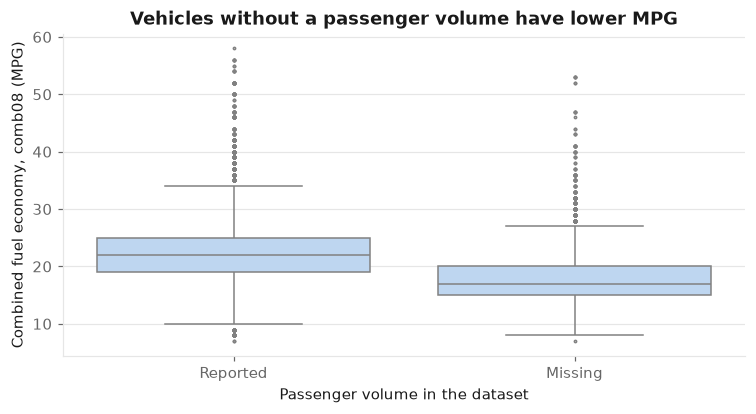

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = pd.DataFrame({TARGET: train[TARGET],
                        "status": np.where(pv_missing, "Missing", "Reported")})
sns.boxplot(data=plot_df, x="status", y=TARGET, order=["Reported", "Missing"], color="#b6d5f8",
            fliersize=1.5, linewidth=1, ax=ax)
ax.set_title("Vehicles without a passenger volume have lower MPG")
ax.set_xlabel("Passenger volume in the dataset")
ax.set_ylabel("Combined fuel economy, comb08 (MPG)")
save(fig, "missing_volume_vs_comb08")
plt.show()

**Observations:** interior volume is **not missing at random**. It is missing mainly for
**pickups, SUVs, vans and two-seaters**, which the EPA does not size this way. These
vehicles have lower MPG (mean about 17.9 vs 22.5). The missing value itself carries
information, which **confirms the decision in notebook 02** to add a "was missing"
indicator next to the median imputation, instead of only filling in the gaps.

### 8.2 Is the target related to `make`?

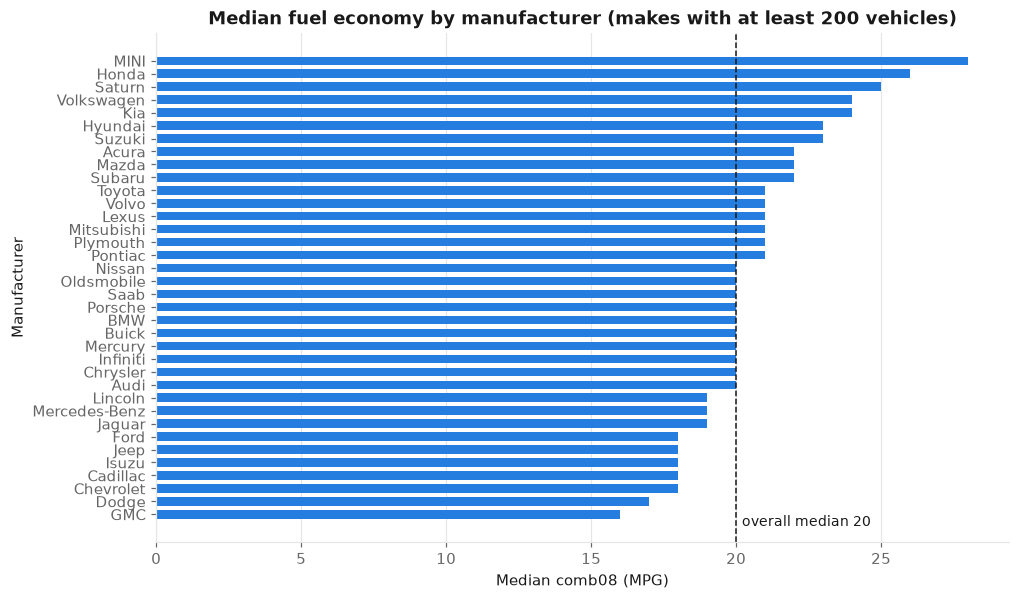

In [30]:
make_stats = train.groupby("make")[TARGET].agg(["count", "median"])
make_stats = make_stats[make_stats["count"] >= 200].sort_values("median")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(make_stats.index, make_stats["median"], color=BLUE, height=0.65)
ax.axvline(y_train.median(), color=TEXT, linestyle="--", linewidth=1)
ax.text(y_train.median() + 0.2, -0.9, f"overall median {y_train.median():g}", color=TEXT, fontsize=9)
ax.set_title("Median fuel economy by manufacturer (makes with at least 200 vehicles)")
ax.set_xlabel("Median comb08 (MPG)")
ax.set_ylabel("Manufacturer")
ax.grid(axis="y", visible=False)
save(fig, "make_vs_comb08")
plt.show()

**Observations:** manufacturers differ clearly, from a median of about 16 MPG (GMC) to
about 28 MPG (MINI). Small-car brands (MINI, Honda, Saturn, Volkswagen, Kia) are above
the overall median, while truck-heavy brands (GMC, Dodge, Chevrolet, Ford, Jeep) are
below. Much of this is explained by the vehicles
they make (class, engine size), but `make` adds some brand-specific information about
engineering choices.

## 9. Key findings

1. **Engine size is the main driver of fuel economy.** `displ` and `cylinders` have
   Spearman correlations of −0.82 and −0.78 with `comb08`.
2. **The relationships are non-linear.** MPG falls steeply for small engines and
   flattens for large ones, and it was flat over time until about 2008 and then rose.
   Spearman is consistently stronger than Pearson for the key features.
3. **Powertrain matters a lot for a small group.** Hybrids and plug-in hybrids (about
   2% of vehicles) reach a median of about 28 to 29 MPG, far above what their engine
   size suggests. They make up almost all of the "unusual for engine size" vehicles.
4. **Vehicle class and drive type add strong information** (pickups/vans/4WD SUVs
   about 14 to 17 MPG vs small cars about 22 to 24), capturing weight and aerodynamics,
   which are not directly in the data.
5. **Technology trends:** more gears, turbocharging and start-stop systems all rise
   over time along with MPG, so these features are partly correlated with `year`.
6. **Multicollinearity:** `displ`–`cylinders` (0.91) and `year`–`trans_speeds` (0.75).
7. **The target is right-skewed** (skew 1.15). The log of the target is almost
   symmetric (0.09).
8. **Outliers are genuine vehicles** (hybrids, diesels, microcars, supercars) and are
   kept.
9. **Missing interior volumes are informative.** They mostly belong to trucks/SUVs with
   lower MPG.
10. **Data-quality issues:** drive-type labels changed around 2009, and a few old records
    have impossible passenger volumes (1 to 6 cu ft).

## 10. How the EDA informs model development

| Finding | Consequence for the models |
|---|---|
| Strong but **curved** relationships; interactions (hybrid × engine size) | **Decision Tree and Random Forest** should outperform Linear Regression. Linear Regression is the interpretable baseline. |
| Features on very different scales | Keep **standard scaling** in the pipeline (needed for Linear Regression, harmless for trees). |
| `displ`–`cylinders` and `year`–`trans_speeds` collinearity | Do **not** interpret individual Linear Regression coefficients as effects. Use permutation importance instead. Ridge regression is an option if coefficients become unstable. |
| Right-skewed target, log almost symmetric | Optionally test Linear Regression on **log(comb08)** (e.g. with `TransformedTargetRegressor`), and compare on the original MPG scale. |
| Hybrids/PHEVs are rare but extreme | Report errors **per powertrain group**, not just overall, so poor performance on hybrids is not hidden by the large conventional group. Consider RMSE *and* MAE, since RMSE is more affected by these vehicles. |
| High-cardinality `make` and `eng_dscr` | Keep the **rare-category grouping** in the one-hot encoder. Limit tree depth (`max_depth`, `min_samples_leaf`) so the Decision Tree does not memorise rare categories. |
| Missing volumes are informative | Keep the **missing-value indicators** from the preprocessing pipeline. |
| A few impossible passenger volumes (1 to 6 cu ft) | Small fix for the preprocessing module: treat values below 40 cu ft as missing. Check these rows in the Linear Regression residuals. |
| The same model appears across years | Expect a slightly optimistic random-split score. Use **cross-validation** on the training set for model selection, and touch the test set once. |
| Pure EVs excluded | State in the report that the models cover **combustion-engine vehicles, hybrids and plug-in hybrids** only. |

**Next step:** train Linear Regression, Decision Tree and Random Forest using
`Pipeline([("preprocess", prep.build_preprocessor()), ("model", ...)])` on the training
data, compare them with cross-validation, and evaluate the final models once on the
test set.